# 01 — Exploration des données NASA POWER (jalon J3)
Équipe Bangré. Démarche en six étapes de la séance 4 : structure, qualité, variables une à une, relations, temps, cible.

In [1]:
import sys, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, '../src')
import nettoyage
brut = nettoyage.lire_brut(nettoyage.BRUT)
print(brut.shape); brut.head()

(16436, 8)


,YEAR,DOY,T2M,T2M_MAX,T2M_MIN,RH2M,WS2M,PRECTOTCORR
0,1981,1,20.17,30.38,12.58,31.46,2.51,0.0
1,1981,2,19.59,30.16,11.99,31.07,2.22,0.0
2,1981,3,18.53,28.55,11.05,34.58,2.24,0.0
3,1981,4,19.11,28.83,11.84,39.32,2.11,0.0
4,1981,5,19.46,29.25,12.48,38.43,2.18,0.0


## 1-2. Structure et qualité

In [2]:
df, journal = nettoyage.nettoyer(brut)
print(df.dtypes)
print('Valeurs -999 :', int((brut[nettoyage.VARIABLES] == -999).sum().sum()))
print('Manquants après nettoyage :', int(df.isna().sum().sum()))
journal

date           datetime64[us]
T2M                   float64
T2M_MAX               float64
T2M_MIN               float64
RH2M                  float64
WS2M                  float64
PRECTOTCORR           float64
dtype: object
Valeurs -999 : 0
Manquants après nettoyage : 0


,etape,defaut,decision,lignes
0,1,Date codée en année + jour de l'année (DOY),Conversion en date calendaire,16436
1,2,Valeurs manquantes codées -999,Remplacées par NaN (aucune imputation),0
2,3,Dates en double,Une seule ligne conservée,0
3,4,Jours absents du calendrier,Lignes recréées et laissées vides (signalées),0
4,5,Valeurs hors bornes physiques,"Écartées (NaN), à examiner une par une",0
5,6,Incohérence T2M_MIN <= T2M <= T2M_MAX,Contrôle seulement (aucune correction),0


## 3. Une variable à la fois

In [3]:
df[nettoyage.VARIABLES].describe().round(2)

,T2M,T2M_MAX,T2M_MIN,RH2M,WS2M,PRECTOTCORR
count,16436.00,16436.00,16436.00,16436.00,16436.00,16436.00
mean,27.48,35.02,21.26,48.99,1.70,2.17
std,3.34,3.49,3.97,23.40,0.63,4.70
min,16.16,23.83,9.33,5.83,0.38,0.00
25%,25.49,32.44,18.38,27.41,1.17,0.00
50%,27.26,34.79,22.20,49.50,1.64,0.10
75%,29.75,37.47,23.85,70.96,2.16,2.65
max,37.30,44.60,31.07,92.90,4.84,140.90


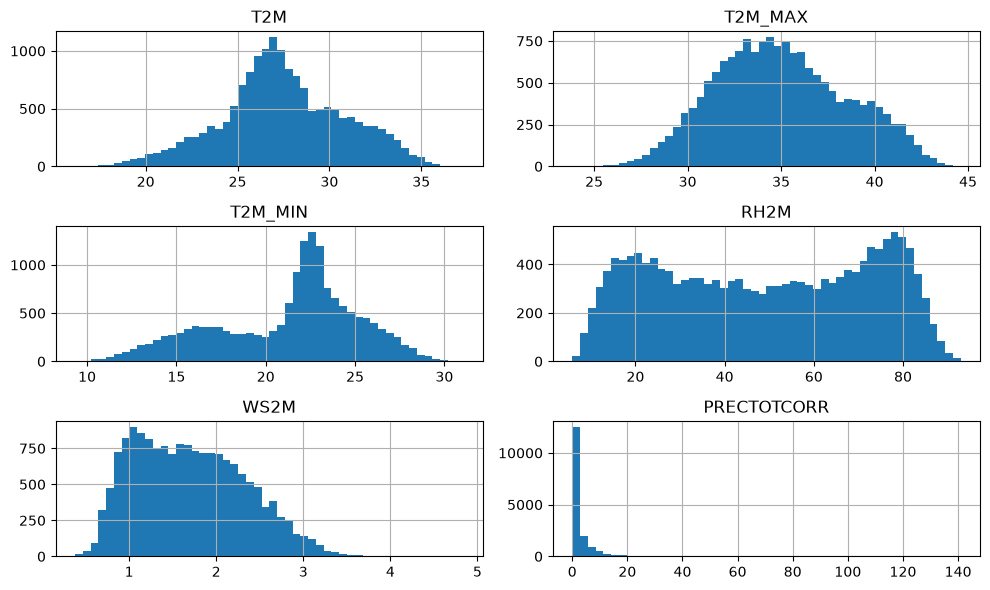

In [4]:
df[nettoyage.VARIABLES].hist(bins=50, figsize=(10, 6)); plt.tight_layout()

## 4-6. Relations, temps et cible
Le script `src/exploration.py` calcule le seuil P95 sur 1981-2015 seul, la part de pics par période, la saisonnalité, l'autocorrélation et produit les figures du rapport.

In [5]:
import exploration
exploration.PROPRE = nettoyage.PROPRE
exploration.main()

{
 "lignes": 16436,
 "colonnes": 7,
 "debut": "1981-01-01",
 "fin": "2025-12-31",
 "manquants": 0,
 "mediane_vs_moyenne_tmax": [
  34.79,
  35.02
 ],
 "iqr_tmax_suspects": 3,
 "jours_sans_pluie_pct": 43.1,
 "seuil_p95_entrainement": 40.94,
 "seuil_p95_tout_fichier": 41.07,
 "part_pics_par_periode_pct": {
  "entrainement": 5.0,
  "validation": 7.4,
  "test": 8.0
 },
 "nb_pics_par_periode": {
  "entrainement": 640,
  "validation": 135,
  "test": 146
 },
 "pics_par_mois": {
  "1": 0,
  "2": 12,
  "3": 185,
  "4": 472,
  "5": 238,
  "6": 14,
  "7": 0,
  "8": 0,
  "9": 0,
  "10": 0,
  "11": 0,
  "12": 0
 },
 "tmax_moyenne_par_mois": {
  "1": 33.1,
  "2": 36.1,
  "3": 38.8,
  "4": 39.8,
  "5": 38.2,
  "6": 35.6,
  "7": 32.8,
  "8": 31.1,
  "9": 32.1,
  "10": 34.6,
  "11": 34.9,
  "12": 33.2
 },
 "tendance_tmax_c_par_decennie": 0.01,
 "tmax_moyenne_par_periode": {
  "entrainement": 35.06,
  "validation": 34.74,
  "test": 34.97
 },
 "episodes_pic": {
  "nombre": 327,
  "duree_moyenne_j": 2.8,


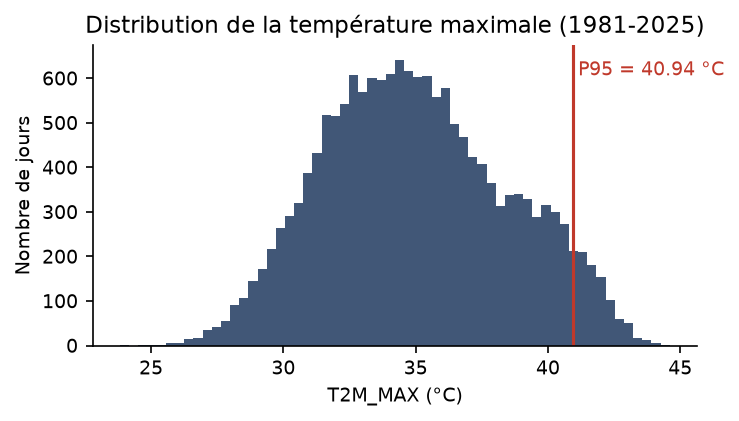

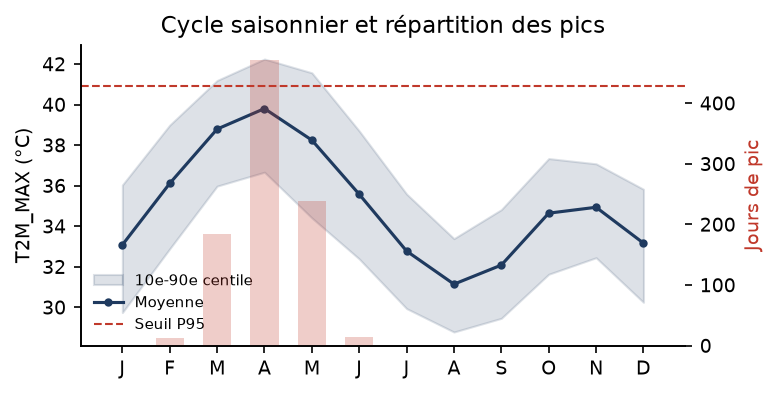

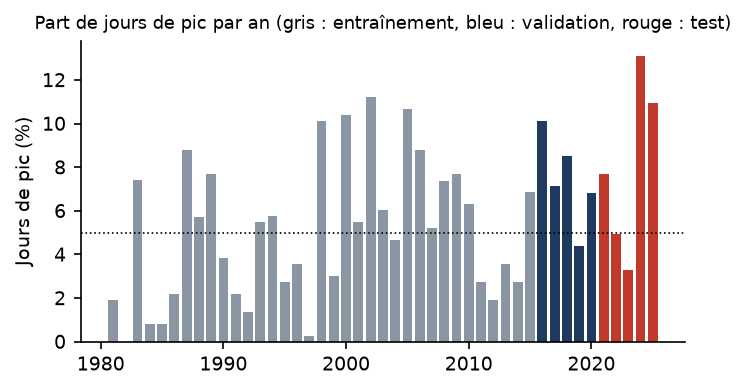

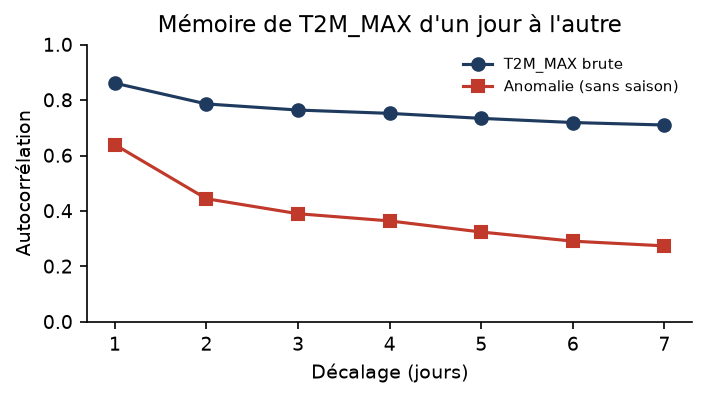

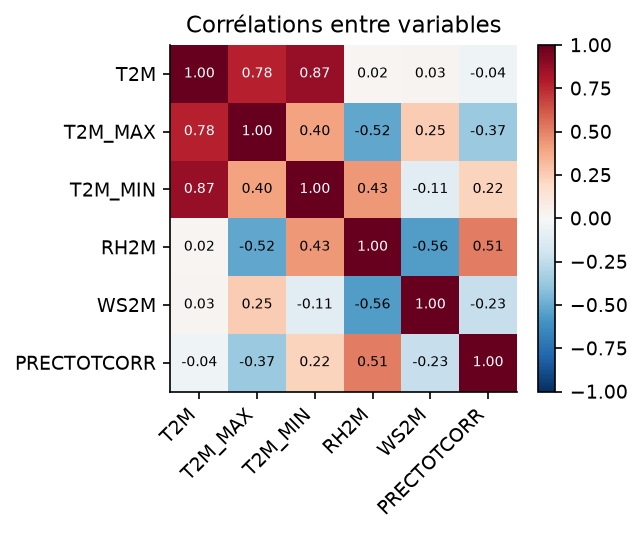

In [6]:
from IPython.display import Image, display
for f in sorted(exploration.FIG.glob('fig*.png')):
    display(Image(filename=str(f), width=520))